<!-- reader-content -->

# Gradients and parameter fitting

<!-- notebook-download -->

Differentiate dressed observables and pulse responses, and fit model
parameters with the derivatives that JAX returns.

## Gradients of spectral observables

A scalar fitting objective has a gradient and a vector residual has a Jacobian, and
both go through the same public `Chip.with_params()` call.

The second observable is the coefficient of $Z n_r$, with
$Z=|0\rangle\langle0|-|1\rangle\langle1|$ and
$\chi_Z=-\mathrm{dispersive\_shift}/2$.
The scalar method returns the full pull $E_{11}-E_{10}-E_{01}+E_{00}$.

In [1]:
import jax
import jax.numpy as jnp
import numpy as np

from quchip import Capacitive, Chip, DuffingTransmon, Resonator

q = DuffingTransmon(freq=5.0, anharmonicity=-0.25, levels=4, label="q")
r = Resonator(freq=7.0, levels=4, label="r")

chip = Chip(
    [q, r],
    [Capacitive(q, r, g=0.05, label="qr")],
    frame="rotating",
    backend="dynamiqs",
)

Define a scalar fitting objective and a vector residual. `jax.grad` gives the loss
gradient, and `jax.jacrev` gives the observable's Jacobian. Sweep the coupling to compare
the resolved curve with its local tangent.

In [2]:
names = ["q.freq", "q.anharmonicity", "qr.g"]
theta = jnp.array([5.0, -0.25, 0.05])
target = jnp.array([5.05, 0.0010])  # [f01, chi_z] in GHz


def observables(th):
    c = chip.with_params(dict(zip(names, th)))
    chi_z = -c.dispersive_shift("q", "r") / 2
    return jnp.stack([jnp.asarray(c.freq("q")), jnp.asarray(chi_z)])


def residual(th):
    return observables(th) - target


def loss(th):
    return jnp.sum(residual(th) ** 2)


static_gradient = jax.grad(loss)(theta)
static_jacobian = jax.jacrev(residual)(theta)
print("Loss gradient:", np.array2string(np.asarray(static_gradient), precision=4))
print("Jacobian, rows [f01, chi_z]:")
print(np.array2string(np.asarray(static_jacobian), precision=4))

coupling_values = jnp.linspace(0.02, 0.08, 61)
observable_sweep = jax.vmap(
    lambda coupling: observables(theta.at[2].set(coupling))
)(coupling_values)
coupling_tangent = observables(theta) + (
    coupling_values[:, None] - theta[2]
) * static_jacobian[:, 2]

Loss gradient: [-1.0243e-01  8.4910e-07  5.1090e-03]
Jacobian, rows [f01, chi_z]:
[[ 9.9938e-01  0.0000e+00 -4.9938e-02]
 [ 1.3059e-04 -4.9285e-04  5.5308e-03]]


<details>
<summary>Plotting code</summary>

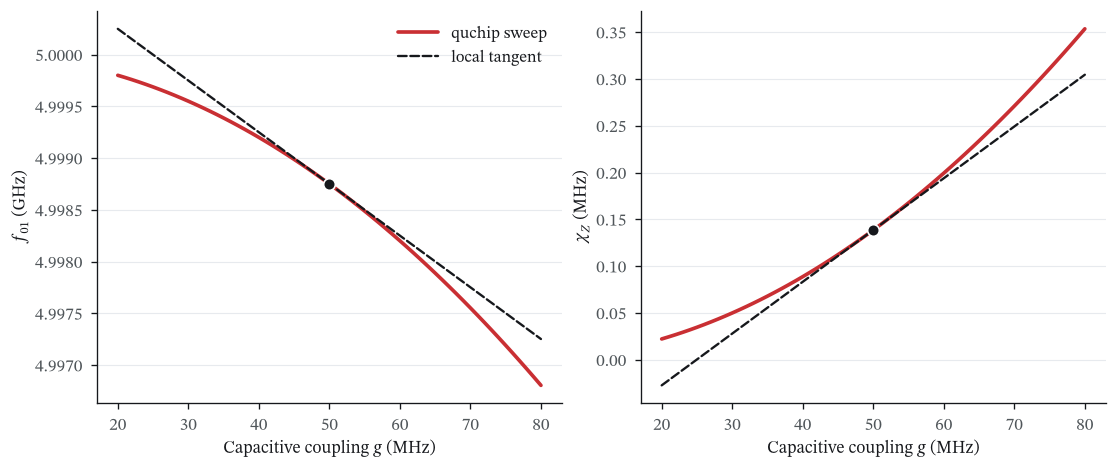

In [3]:
import shutil
from pathlib import Path
import matplotlib.pyplot as plt

# In a quchip checkout, use the documentation style and save the figures there.
docs = Path("../docs")
if docs.is_dir():
    plt.style.use(docs / "_static/quchip.mplstyle")
plt.rcParams["text.usetex"] = bool(shutil.which("latex"))

static_figure, static_axes = plt.subplots(1, 2, figsize=(9.2, 3.8), layout="constrained")
for observable_index, (axis, ylabel, scale) in enumerate(
    zip(
        static_axes,
        (r"$f_{01}$ (GHz)", r"$\chi_Z$ (MHz)"),
        (1.0, 1.0e3),
        strict=True,
    )
):
    axis.plot(
        1.0e3 * coupling_values,
        scale * observable_sweep[:, observable_index],
        color="#C92F33",
        linewidth=2.2,
        label="quchip sweep",
    )
    axis.plot(
        1.0e3 * coupling_values,
        scale * coupling_tangent[:, observable_index],
        color="#16181C",
        linestyle="--",
        linewidth=1.4,
        label="local tangent",
    )
    axis.plot(
        1.0e3 * theta[2],
        scale * observables(theta)[observable_index],
        marker="o",
        color="#16181C",
        markeredgecolor="white",
        markersize=7,
        linestyle="none",
    )
    axis.set(xlabel=r"Capacitive coupling $g$ (MHz)", ylabel=ylabel)

static_axes[0].legend()

if docs.is_dir():
    static_figure.savefig(docs / "images/differentiate_static_slope.svg")
plt.show()

</details>

```{figure} ../images/differentiate_static_slope.svg
:width: 760px
:alt: Qubit frequency and dispersive shift swept over capacitive coupling with local tangent lines at 50 megahertz

The black point is where `jax.jacrev` evaluates the slope. The dispersive shift
bends away from its tangent faster than $f_{01}$ over this range.
```

## Fit two parameters

Hold the anharmonicity fixed and fit the qubit frequency and the coupling to
the two targets. SciPy's `least_squares` takes the residual and its JAX
Jacobian, and since there are two parameters and two targets, the fit finds a
zero of the residual.

In [4]:
from scipy.optimize import least_squares

fitted_indices = jnp.array([0, 2])  # q.freq and qr.g


def fit_residual(values):
    return residual(theta.at[fitted_indices].set(values))


fit_jacobian = jax.jit(jax.jacrev(fit_residual))
fit = least_squares(
    lambda values: np.asarray(fit_residual(jnp.asarray(values))),
    np.asarray(theta[fitted_indices]),
    jac=lambda values: np.asarray(fit_jacobian(jnp.asarray(values))),
)
fitted = observables(theta.at[fitted_indices].set(fit.x))
print(f"q.freq = {fit.x[0]:.6f} GHz, qr.g = {1e3 * fit.x[1]:.3f} MHz")
print(f"f01 = {float(fitted[0]):.6f} GHz, chi_Z = {1e3 * float(fitted[1]):.4f} MHz")

q.freq = 5.058868 GHz, qr.g = 131.498 MHz
f01 = 5.050000 GHz, chi_Z = 1.0000 MHz


A scalar optimizer, such as `scipy.optimize.minimize`, takes `loss` and
`jax.grad(loss)` instead. To fit measured spectroscopy with held-out points,
see the [fluxonium spectroscopy study](../studies/fluxonium-spectroscopy.md).

## Differentiate a pulse response

Differentiate the final excited-state population with respect to pulse
amplitude, Gaussian shape, and detuning.

The dynamiqs backend keeps these defined parameters differentiable through
the time-domain solve. Install the backend with
`pip install 'quchip[dynamiqs]'`.

In [5]:
from quchip import RWA, ChargeDrive, Chip, DuffingTransmon, Gaussian, QuantumSequence

amplitude0 = 0.029
frequency0 = 5.0
sigmas0 = 3.0

qubit = DuffingTransmon(
    freq=frequency0,
    anharmonicity=-0.30,
    levels=3,
    label="q",
)

chip = Chip(
    [qubit],
    frame="rotating",
    approximation=RWA(),
    backend="dynamiqs",
)
drive = ChargeDrive(qubit, label="xy")
_ = chip.wire(drive)

sequence = QuantumSequence(chip)
_ = sequence.schedule(
    drive,
    envelope=Gaussian(duration=40.0, sigmas=sigmas0, amplitude=amplitude0),
    freq=frequency0,
)

times = jnp.linspace(0.0, 60.0, 121)
original_parameters = dict(sequence.parameters)

One unit in the perturbation vector means $1\%$ in pulse amplitude, $1\%$ in
the Gaussian parameter $N_\sigma$, or $1$ MHz in pulse detuning. quchip defines
$\sigma=\mathrm{duration}/(2N_\sigma)$, so increasing $N_\sigma$ by $1\%$
narrows the physical Gaussian width by approximately $1\%$. The derivatives
predict changes in final population on these three scales. `jax.value_and_grad`
returns the population and its derivatives together.

In [6]:
parameter_paths = ("pulse.0.amplitude", "pulse.0.sigmas", "pulse.0.freq")
perturbation_labels = (
    r"amplitude (+1\%)",
    r"$N_\sigma$ (+1\%; $\sigma$ $-$1\%)",
    "detuning (+1 MHz)",
)


def final_population(perturbation):
    rebound = sequence.with_params(
        {
            "pulse.0.amplitude": amplitude0 * (1.0 + 0.01 * perturbation[0]),
            "pulse.0.sigmas": sigmas0 * (1.0 + 0.01 * perturbation[1]),
            "pulse.0.freq": frequency0 + perturbation[2] * 1.0e-3,
        }
    )
    result = rebound.simulate(
        tlist=times,
        initial_state={"q": 0},
    )
    return jnp.real(result.population("q", level=1)[-1])


origin = jnp.zeros(3)
population0, gradient = jax.jit(jax.value_and_grad(final_population))(origin)
print(f"Final P(q=1) = {float(population0):.4f}")
for path, value in zip(parameter_paths, np.asarray(gradient)):
    print(f"Change per unit of {path}: {value:+.3e}")

Final P(q=1) = 0.9955
Change per unit of pulse.0.amplitude: +1.576e-03
Change per unit of pulse.0.sigmas: -1.567e-03
Change per unit of pulse.0.freq: +3.378e-03


At this operating point, increasing amplitude or detuning raises the
final population, and a narrower Gaussian lowers it.

<details>
<summary>Plotting code</summary>

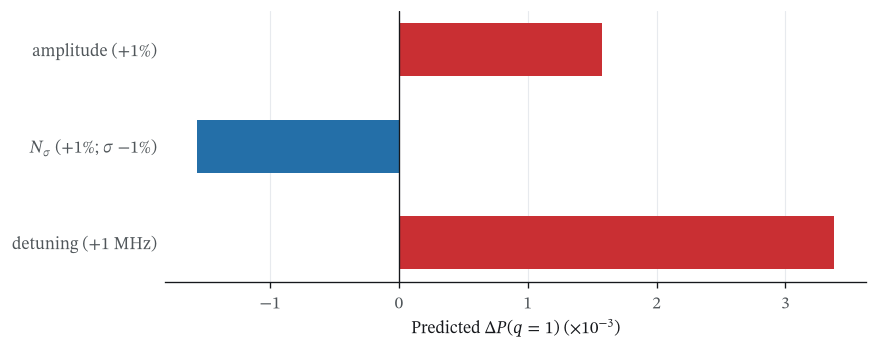

In [7]:
impact = np.asarray(gradient) * 1000

figure, axis = plt.subplots(figsize=(7.2, 2.8), layout="constrained")
axis.barh(perturbation_labels, impact, height=0.55,
          color=["#C92F33" if value >= 0 else "#246FA8" for value in impact])
axis.axvline(0, color="#16181C", lw=0.8)
axis.set(xlabel=r"Predicted $\Delta P(q=1)$ ($\times 10^{-3}$)")
axis.invert_yaxis()
axis.grid(False, axis="y")
axis.grid(True, axis="x")
axis.spines["left"].set_visible(False)
axis.tick_params(axis="y", length=0)

if docs.is_dir():
    figure.savefig(docs / "images/differentiate_a_driven_chip.svg")
plt.show()

</details>

```{figure} ../images/differentiate_a_driven_chip.svg
:width: 720px
:alt: Final excited-state population sensitivities to amplitude, pulse width and detuning.

Each bar predicts the population change for the perturbation named on its axis.
```

<details>
<summary>Advanced: share calibration parameters across three experiments</summary>

Combine three pulse experiments with a shared qubit frequency, amplitude
scale, and carrier correction, while their durations and nominal detunings stay
fixed.

In [8]:
experiment_settings = (
    (18.0, 0.020, -0.004),
    (28.0, 0.026, 0.000),
    (40.0, 0.029, 0.004),
)
experiments = []
for duration, amplitude, carrier_offset in experiment_settings:
    experiment = QuantumSequence(chip)
    experiment.schedule(
        drive,
        envelope=Gaussian(duration=duration, sigmas=3.0, amplitude=amplitude),
        freq=frequency0 + carrier_offset,
    )
    experiments.append(experiment)

shared_names = ("q.freq", "amplitude scale", "carrier correction")
shared_origin = jnp.array([frequency0, 1.0, 0.0])
multi_times = jnp.linspace(0.0, 60.0, 81)

Rebind the shared parameters across the three schedules and collect their final populations.

In [9]:
def experiment_outputs(shared):
    qubit_frequency, amplitude_scale, carrier_correction = shared
    values = []
    for experiment, (_, nominal_amplitude, nominal_offset) in zip(
        experiments, experiment_settings
    ):
        rebound = experiment.with_params(
            {
                "q.freq": qubit_frequency,
                "pulse.0.amplitude": nominal_amplitude * amplitude_scale,
                "pulse.0.freq": frequency0 + nominal_offset + carrier_correction,
            }
        )
        result = rebound.simulate(
            tlist=multi_times,
            initial_state={"q": 0},
        )
        values.append(jnp.real(result.population("q", level=1)[-1]))
    return jnp.stack(values)

Combine the experiment residuals into one weighted calibration loss.

In [10]:
reference_outputs = experiment_outputs(shared_origin)
multi_targets = jax.lax.stop_gradient(
    reference_outputs + jnp.array([0.010, -0.015, 0.005])
)
experiment_weights = jnp.array([1.0, 2.0, 0.5])


def multi_residual(shared):
    return experiment_outputs(shared) - multi_targets


def multi_loss(shared):
    return jnp.sum(experiment_weights * multi_residual(shared) ** 2)

The Jacobian has one row for each experiment and one column for each shared parameter.

In [11]:
multi_jacobian = jax.jacrev(multi_residual)(shared_origin)
multi_loss_gradient = jax.grad(multi_loss)(shared_origin)
print(f"Jacobian, one row for each experiment, columns {shared_names}:")
print(np.array2string(np.asarray(multi_jacobian), precision=3))

Jacobian, one row for each experiment, columns ('q.freq', 'amplitude scale', 'carrier correction'):
[[ -0.632   0.377   0.632]
 [ -0.797   0.896   0.797]
 [ 11.594   0.179 -11.594]]


Use the Jacobian to see which experiment constrains each parameter, and
the loss gradient for an optimization step.

<details>
<summary>Numerical checks</summary>

In [12]:
assert sequence.simulate(tlist=times, initial_state={"q": 0}).solver == "sesolve"
assert dict(sequence.parameters) == original_parameters
assert multi_jacobian.shape == (len(experiments), len(shared_names))

</details>

</details>

## Gradient assumptions and limits

The traced calculation keeps the device graph, Hilbert-space dimensions, and
RWA band selection fixed. dynamiqs supports this automatic-differentiation
path, while QuTiP remains available for ordinary solves and sweeps but does not
give gradients. Near degenerate subspaces, be careful with eigenvector
derivatives. Devices that are diagonal by construction, such as
`DuffingTransmon`, keep the level order that the device defines under tracing. A traced
call raises when its values put those levels out of energy order, for example
when a transmon spectrum turns over within its levels. Gradients inherit the
solver tolerances, local-basis truncation, frame, approximation, and loss
scaling of the forward calculation.